In [2]:
import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path

from pyoculus.fields.slab_bfield_two_pert import SlabBfieldTwoPert
from pyoculus.maps import ToroidalBfieldSection
from pyoculus.solvers import PoincarePlot

In [33]:
results_dir = Path("num_results_loc/computed_manifolds")
poincare_dir = Path("num_results_loc/poincare_plots")

configs = list(range(11, 20)) + list(range(110, 116)) + [21, 22, 23]

manifolds = {}
parameters = {}
poincare_plots = {}

for config_id in configs:
    # Load manifolds
    path = results_dir / f"manifolds_{config_id}.npz"
    with np.load(path) as data:
        manifolds[config_id] = {
            key: data[key].copy()
            for key in data.files
        }

    # Load parameters
    path_json = results_dir / f"parameters_{config_id}.json"
    with open(path_json, "r", encoding="utf-8") as f:
        parameters[config_id] = json.load(f)

    # Load Poincare trajectories
    path_poincare = poincare_dir / f"pplot_{config_id}.npz"
    with np.load(path_poincare) as data:
        poincare_plots[config_id] = data["hits"].copy()

In [4]:
def plot_configuration(config_id, markersize=3, poincare=True, unwrapped=False, maxs=None, maxu=None):

    params = parameters[config_id]
    data = manifolds[config_id]

    # Plot the previously computed Poincare plot
    fig, ax = plt.subplots(figsize=(8, 6))

    if poincare:
        if config_id not in poincare_plots:
            raise ValueError(
                f"Poincare plot for configuration {config_id} has not been loaded."
            )

        hits = poincare_plots[config_id]

        for traj in hits:
            ax.scatter(
                traj[:, 0],
                traj[:, 1],
                color="black",
                marker=".",
                s=0.5,
                lw=0
            )

        ax.set_xlim(0, 2)

    # Find indices of all saved manifolds
    indices = sorted(
        int(key[len("stable"):])
        for key in data
        if key.startswith("stable") and key[len("stable"):].isdigit()
    )

    # Default: plot all points
    if maxs is None:
        maxs = [None]*len(indices)

    if maxu is None:
        maxu = [None]*len(indices)

    if len(maxs) != len(indices) or len(maxu) != len(indices):
        raise ValueError(
            f"Configuration {config_id} has {len(indices)} manifolds. "
            "maxs and maxu must have one entry per manifold."
        )

    # Plot stable and unstable manifolds
    first_plotted = True

    for j, i in enumerate(indices):

        # Default: use original arrays
        stable_key = f"stable{i}"
        unstable_key = f"unstable{i}"

        if unwrapped:
            # Prefer unwrapped arrays, if available
            if f"stable_unwrapped{i}" in data:
                stable_key = f"stable_unwrapped{i}"

            if f"unstable_unwrapped{i}" in data:
                unstable_key = f"unstable_unwrapped{i}"

        if stable_key not in data or unstable_key not in data:
            continue

        stable = data[stable_key]
        unstable = data[unstable_key]

        ax.plot(
            stable[:maxs[j], 0], stable[:maxs[j], 1],
            color="blue", marker=".", markersize=markersize,
            linestyle="",
            label="Stable" if first_plotted else None
        )

        ax.plot(
            unstable[:maxu[j], 0], unstable[:maxu[j], 1],
            color="red", marker=".", markersize=markersize,
            linestyle="",
            label="Unstable" if first_plotted else None
        )

        first_plotted = False

    ax.set_title(
        rf"$m_1={params['m1']},\ n_1={params['n1']},\ \delta_1={params['delta1']},\ "
        rf"m_2={params['m2']},\ n_2={params['n2']},\ \delta_2={params['delta2']},\ "
        rf"\iota'={params['iota_prime']}$"
    )

    ax.set_xlabel("x")
    ax.set_ylabel(r"$\theta$")

    return fig, ax

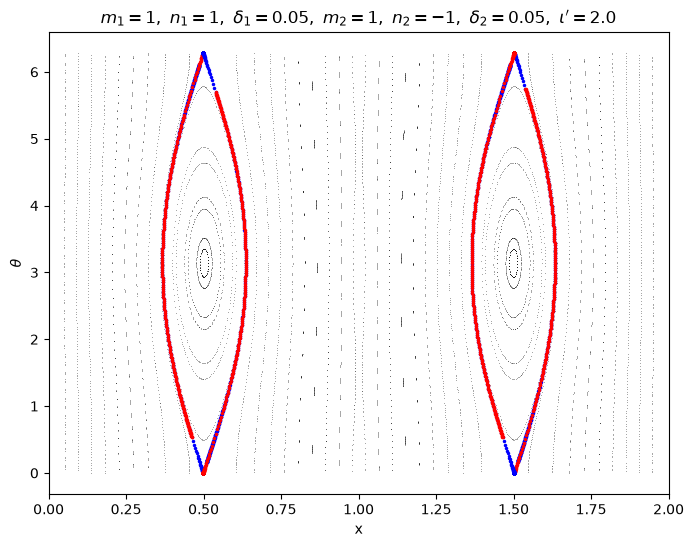

In [5]:
config_id = 11
fig, ax = plot_configuration(config_id)
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

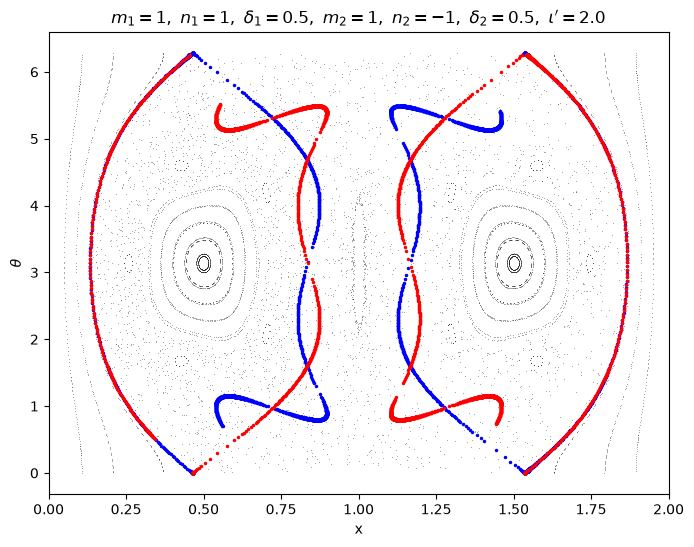

In [19]:
config_id = 12
fig, ax = plot_configuration(config_id, unwrapped=True, maxs=[1350, 700, 700, 1650], maxu=[2100, 700, 800, 1650])
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

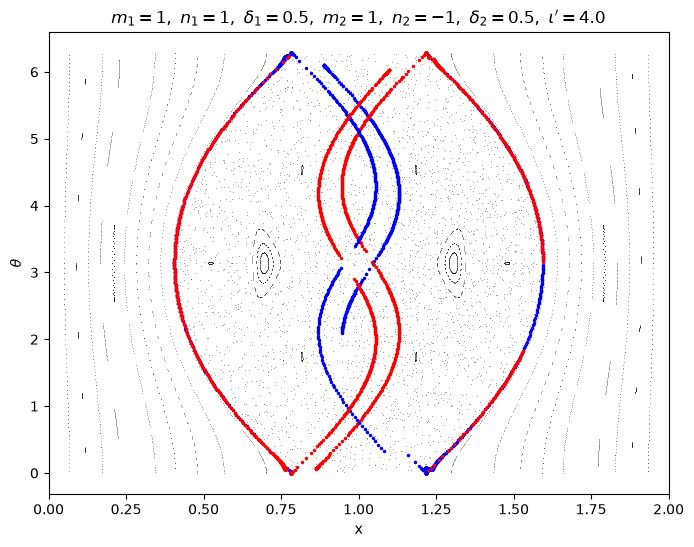

In [57]:
config_id = 13
fig, ax = plot_configuration(config_id, unwrapped=True, maxs=[1500, 300, 1000, 260], maxu=[300, 350, 400, 350])
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

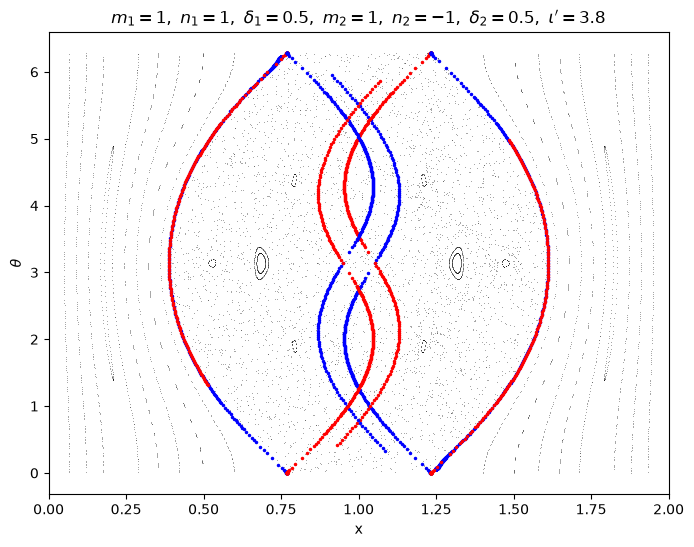

In [58]:
config_id = 14
fig, ax = plot_configuration(config_id, unwrapped=True, maxs=[260, 500, 500, 260], maxu=[265, None, None, 265])
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

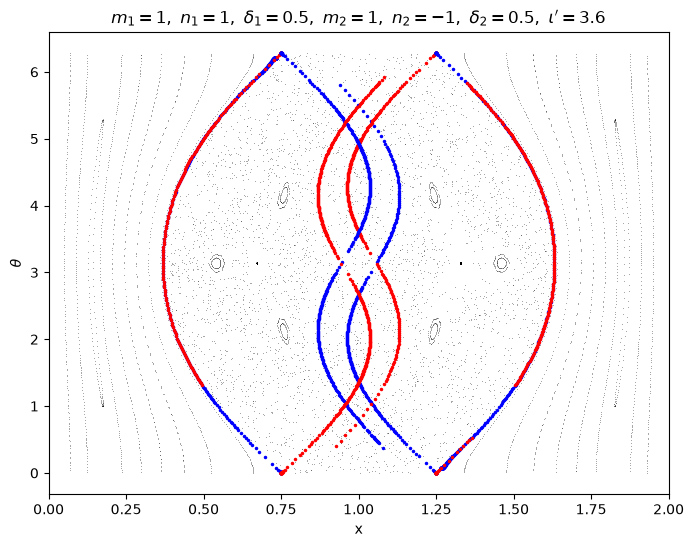

In [59]:
config_id = 15
fig, ax = plot_configuration(config_id, unwrapped=True, maxs=[260,500,500,340], maxu=[260,500,500,340])
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

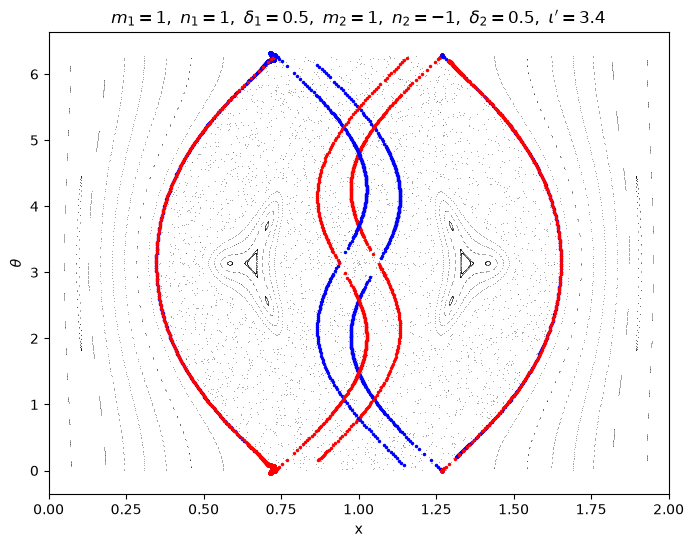

In [89]:
config_id = 16
fig, ax = plot_configuration(config_id, unwrapped=True, maxs=[335,4500,None,288], maxu=[305,380,None,295])#, maxs=[1000,1000,None,280], maxu=[290,370,None,290])
# stable1=stable2, unstable1=unstable2
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

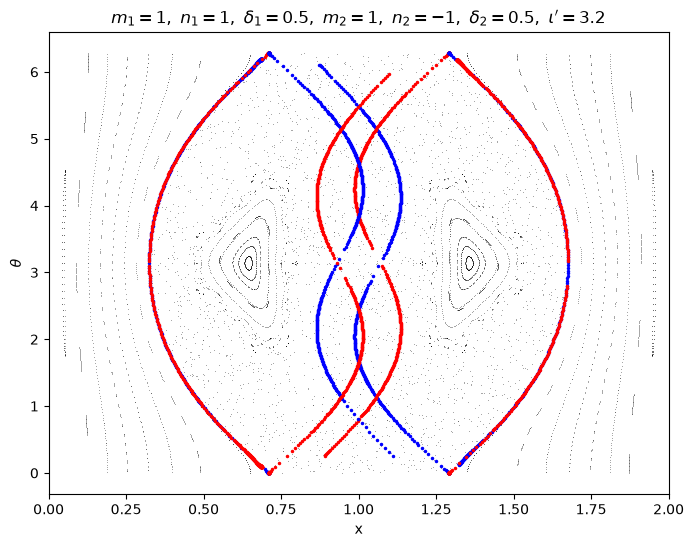

In [90]:
config_id = 17
fig, ax = plot_configuration(config_id, unwrapped=True, maxs=[350,300,None,337], maxu=[360,None,None,350])
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

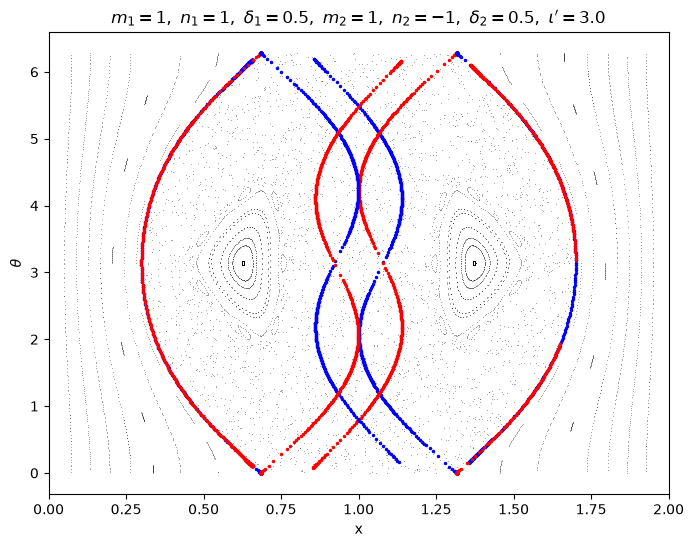

In [91]:
config_id = 18
fig, ax = plot_configuration(config_id, unwrapped=True, maxs=[370,300,None,355], maxu=[380,None,None,380])
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

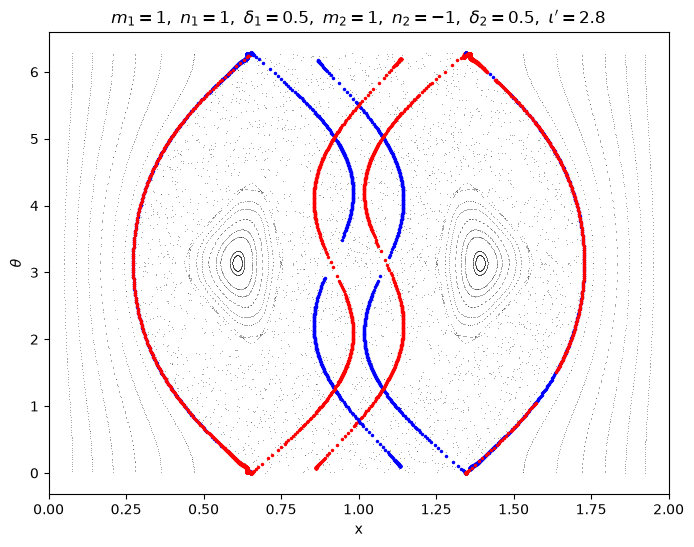

In [92]:
config_id = 19
fig, ax = plot_configuration(config_id, unwrapped=True, maxs=[370,None,None,400], maxu=[400,None,None,400])
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

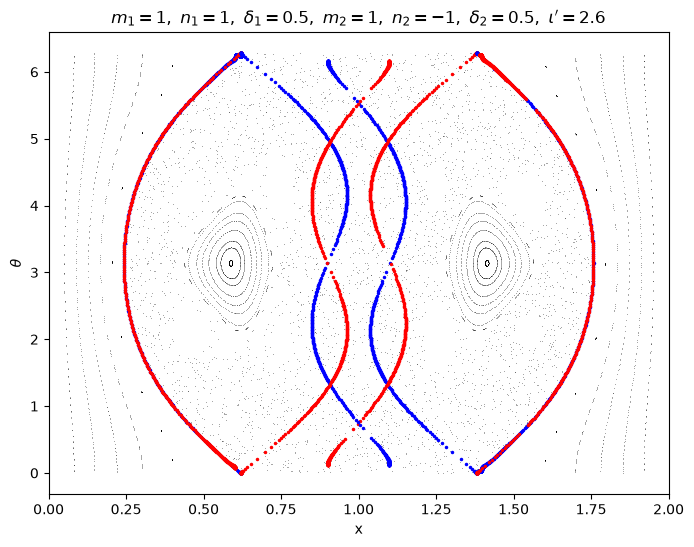

In [93]:
config_id = 110
fig, ax = plot_configuration(config_id, unwrapped=True, maxs=[500,None,None,500], maxu=[500,None,None,500])
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

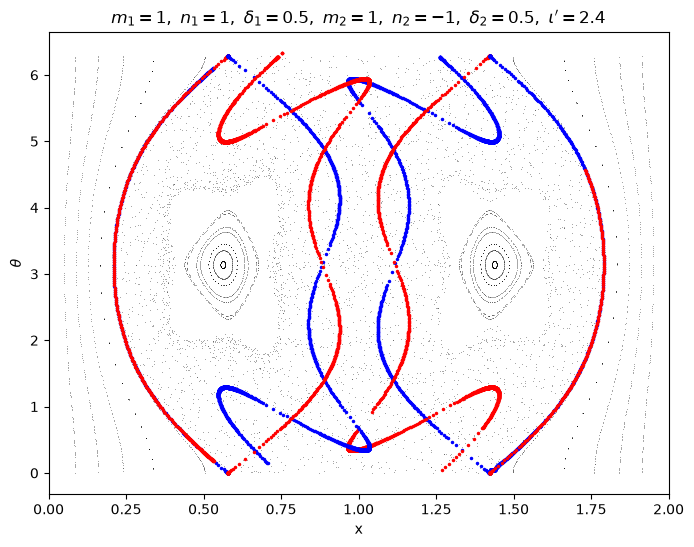

In [147]:
config_id = 111
fig, ax = plot_configuration(config_id, unwrapped=True, maxs=[1550,None,None,1600], maxu=[2100,None,None,1640])
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

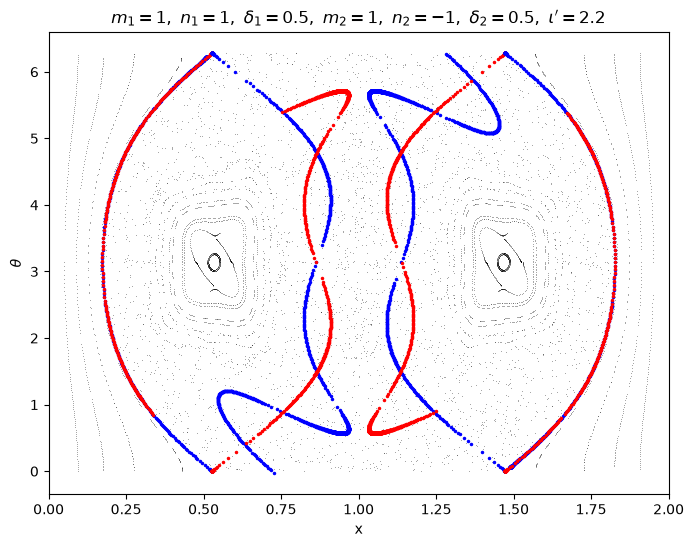

In [117]:
config_id = 112
fig, ax = plot_configuration(config_id, unwrapped=True, maxs=[1800,None,None,1800], maxu=[None,None,None,None])
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

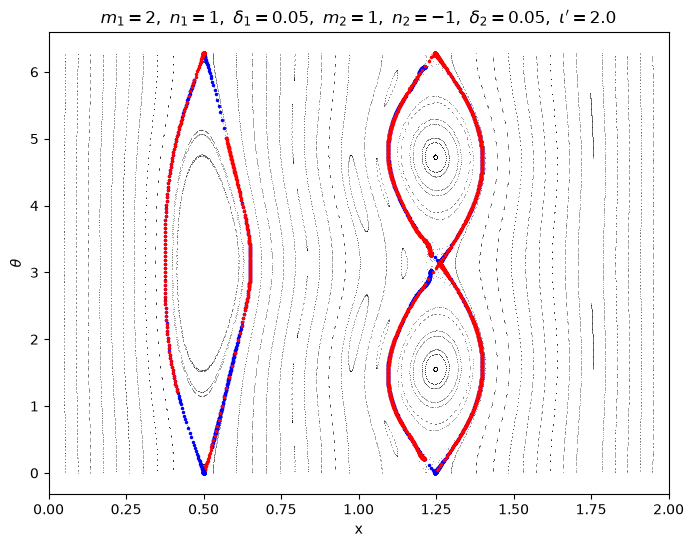

In [94]:
config_id = 21
fig, ax = plot_configuration(config_id, unwrapped=True, maxs=[500,530,500,500,None,None], maxu=[500,530,500,500,None,None])
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

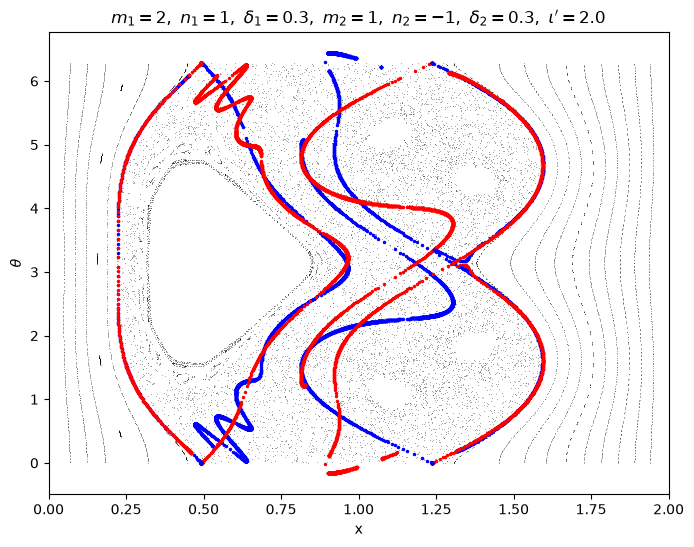

In [102]:
config_id = 22
fig, ax = plot_configuration(config_id, unwrapped=True, maxs=[400,1800,1000,350,None,None], maxu=[340,700,1400,500,2520,None])#maxs=[400,1800,1000,500,None,None], maxu=[300,700,1400,500,None,None]
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

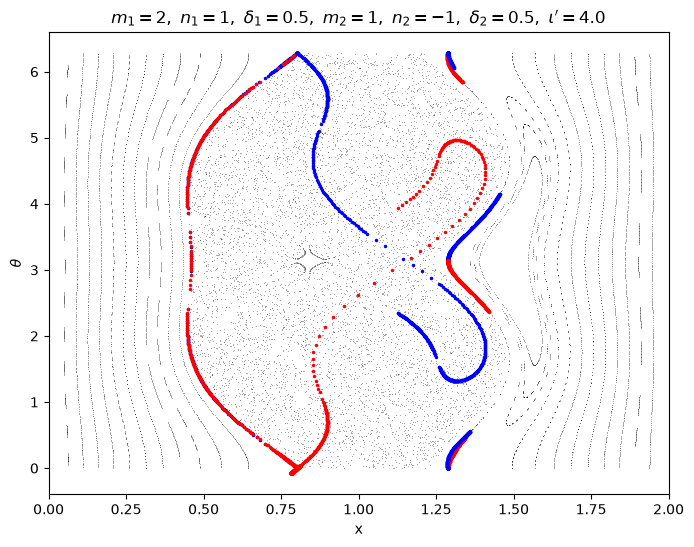

In [103]:
config_id = 23
fig, ax = plot_configuration(config_id, unwrapped=True, maxs=[None,None,None,None,400,570], maxu=[None,None,None,None,None,257])
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

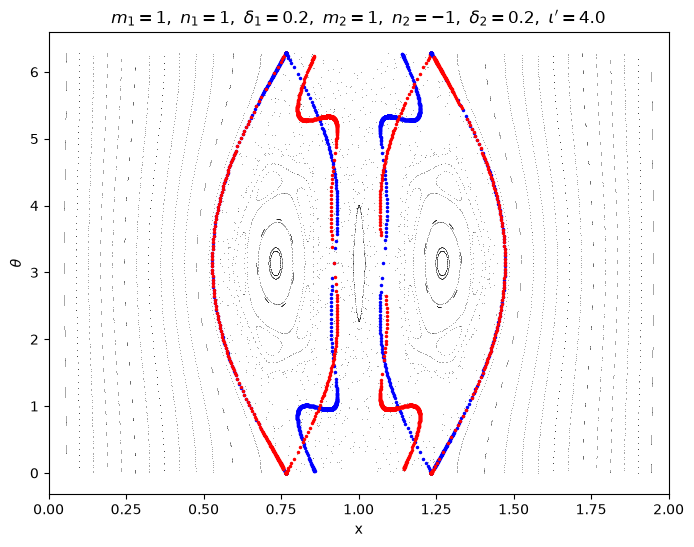

In [46]:
config_id = 113
fig, ax = plot_configuration(config_id, unwrapped=True, maxs=[1650,None,None,1650], maxu=[1650,None,None,1650])
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

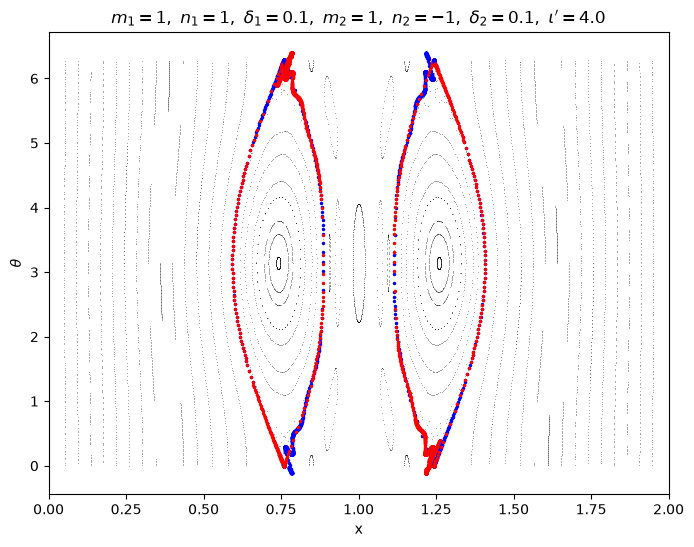

In [63]:
config_id = 114
fig, ax = plot_configuration(config_id, unwrapped=True, maxs=[2200,None,None,2200], maxu=[2200,None,None,2200])
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")

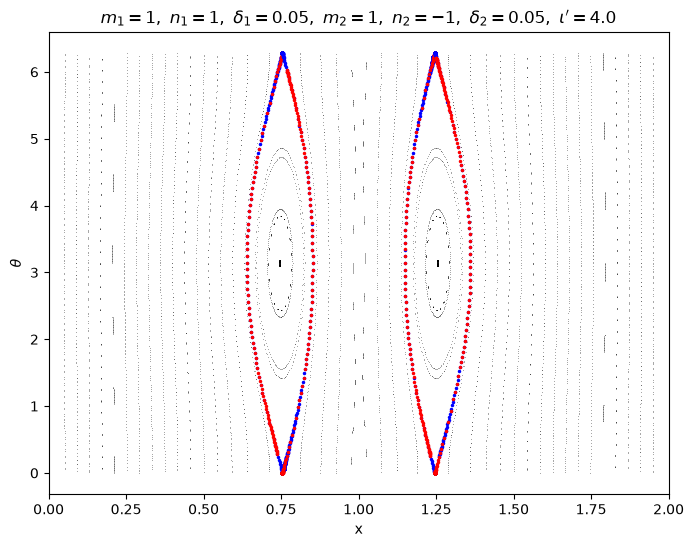

In [64]:
config_id = 115
fig, ax = plot_configuration(config_id, unwrapped=True, maxs=[None,None,None,None], maxu=[None,None,None,None])
plt.show()
save_dir = Path("Figures") / f"config{config_id}"
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"config{config_id}.png", dpi=300, bbox_inches="tight")